In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from dotenv import load_dotenv

In [15]:
import sys
sys.path.append('..')
from utils.visualize_helper import ( 
highlight_max, 
 title_labels, 
 annotate_bars
 )

In [16]:
load_dotenv()
PROJECT_ROOT = os.getenv('PROJECT_ROOT')
df = pd.read_parquet(f"{PROJECT_ROOT}/data/processed/student_performance_cleaned.parquet")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         5000 non-null   uint8  
 1   Class                       5000 non-null   uint8  
 2   Study_Hours_Per_Day         5000 non-null   float64
 3   Attendance_Percentage       5000 non-null   uint8  
 4   Parental_Education          5000 non-null   str    
 5   Internet_Access             5000 non-null   bool   
 6   Extracurricular_Activities  5000 non-null   bool   
 7   Previous_Year_Score         5000 non-null   int64  
 8   Pass_Fail                   5000 non-null   uint8  
 9   Is_Male                     5000 non-null   uint8  
dtypes: bool(2), float64(1), int64(1), str(1), uint8(5)
memory usage: 202.0 KB


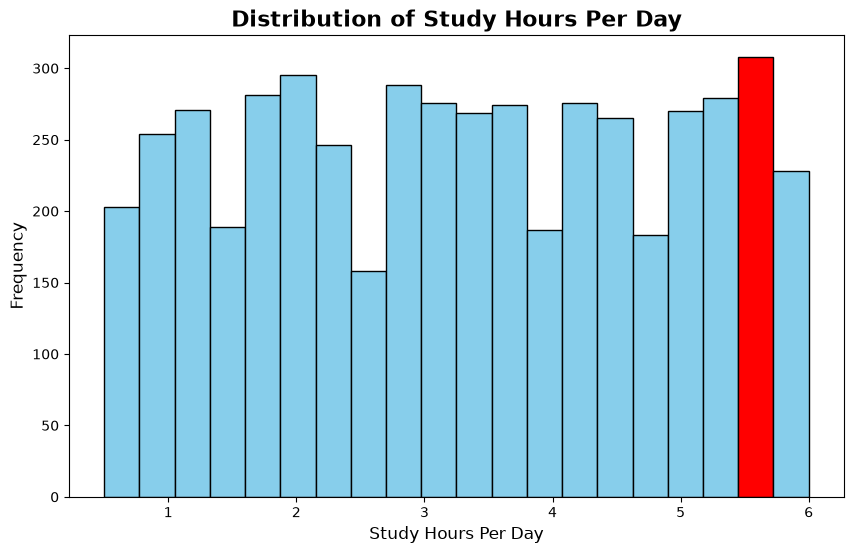

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    df['Study_Hours_Per_Day'],
    bins=20,
    color='skyblue',
    edgecolor='black'
)
title_labels(
    'Distribution of Study Hours Per Day',
    'Study Hours Per Day',
    'Frequency'
)

highlight_max(ax)

plt.show()

#### Observations 
Study hours are spread almost uniformly from 0.5 to 6 hours, with the highest frequency (~310) near 5.6 hours and the lowest (~160) near 2.5 hours no strong concentration in any range.

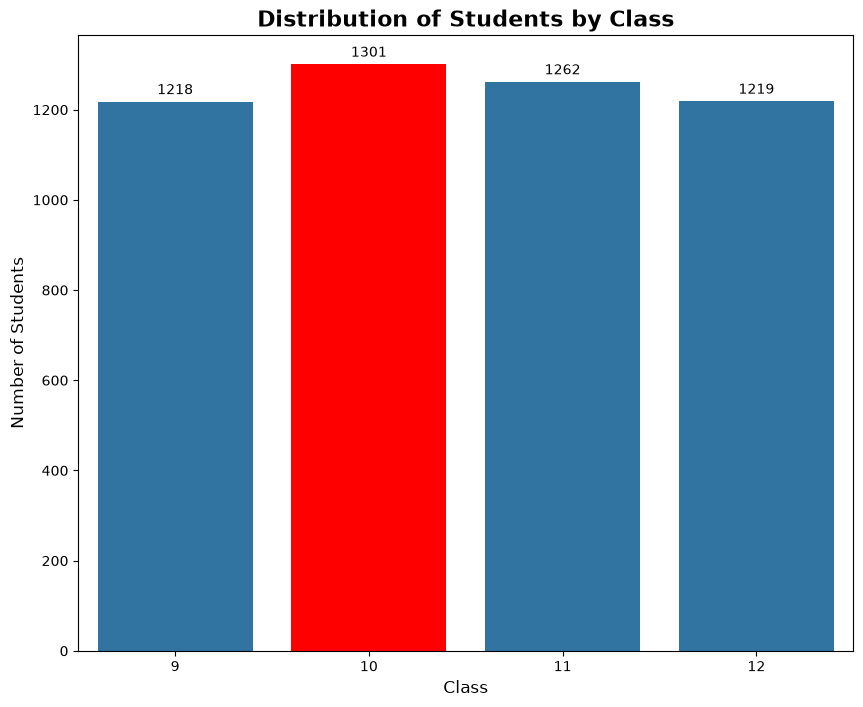

In [18]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.countplot(
    x='Class',
    data=df,
    ax=ax
)
highlight_max(ax)
title_labels(
    'Distribution of Students by Class',
    'Class',
    'Number of Students'
)
annotate_bars(ax)
plt.show()

### Observations:
- The dataset contains four classes: 9, 10, 11, and 12.
- Class 10 has the highest number of students (1,301), followed by Class 11 (1,262), Class 12 (1,219), and Class 9 (1,218).
- The student distribution across classes is relatively balanced, with no significant differences in class sizes.

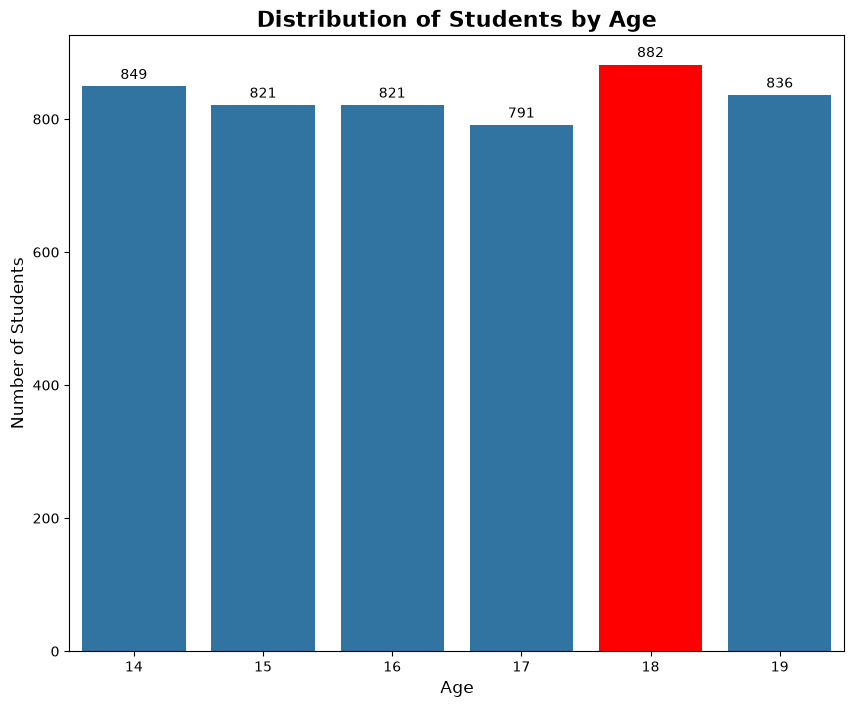

In [19]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.countplot(
    x = 'Age',
    data=df,
    ax=ax
)
title_labels(
    'Distribution of Students by Age',
    'Age',
    'Number of Students'
)
highlight_max(ax)
annotate_bars(ax)
plt.show()

#### Observations: 
- The dataset contains six age groups, ranging from 14 to 19 years.
- The number of students per age group ranges from 197 to 882.
- The age distribution is relatively balanced, although some age groups have noticeably more students than others.

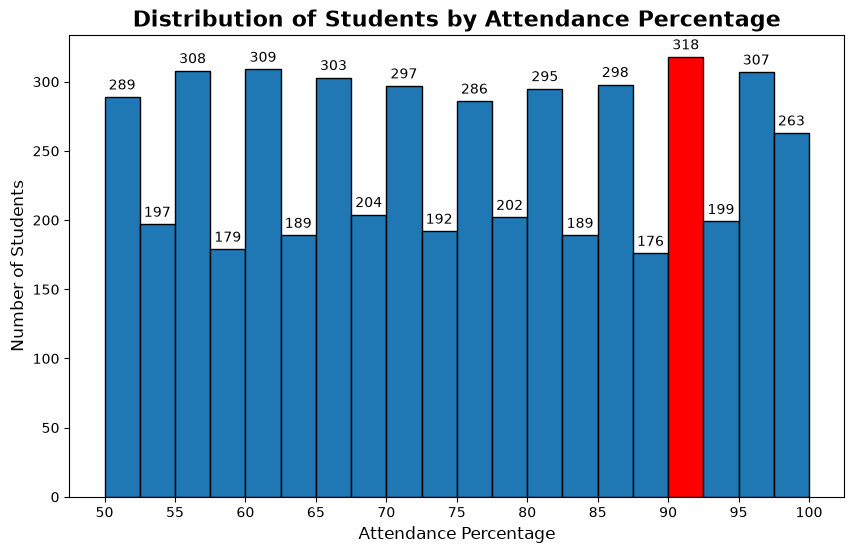

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(
    df['Attendance_Percentage'],
    bins=20,
    edgecolor='black'
)
title_labels(
    'Distribution of Students by Attendance Percentage',
    'Attendance Percentage',
    'Number of Students'
)
plt.xticks(np.arange(50, 105, 5))
highlight_max(ax)
annotate_bars(ax)

plt.show()

### Observation

- Attendance percentages show some variation across the ranges, with student counts mostly between 176 and 318.
- The 90–92% range has the highest number of students (318), while the 88–90% range has the lowest (176).
- Overall, attendance is more concentrated in the mid-to-high ranges, particularly 60–70% and 90–100%.

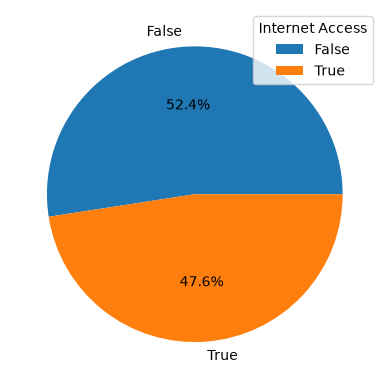

In [21]:
plt.pie(
    df['Internet_Access'].value_counts(),
    labels=df['Internet_Access'].value_counts().index,
    autopct= '%1.1f%%',
)
plt.legend(title='Internet Access', loc='upper right')
plt.show()

### Observations: 
- 52.4% of students has **NO** internet access.
- 47.6% of students **does** have internet access.
- The distribution is relatively balanced, with a slightly higher proportion of students lacking internet access.

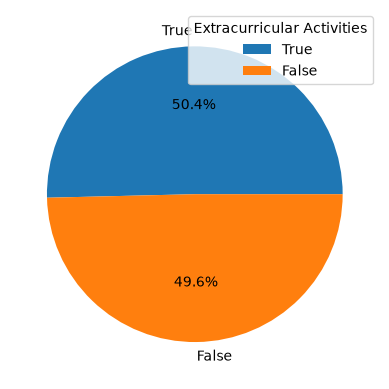

In [22]:
plt.pie(
    df['Extracurricular_Activities'].value_counts(),
    labels=df['Extracurricular_Activities'].value_counts().index,
    autopct= '%1.1f%%',
)
plt.legend(title='Extracurricular Activities', loc='upper right')
plt.show()

### Observations

- 49.6% of students do not participate in extracurricular activities.
- 50.4% of students participate in extracurricular activities.
- The distribution is almost perfectly balanced, with a slight majority of students participating in extracurricular activities.

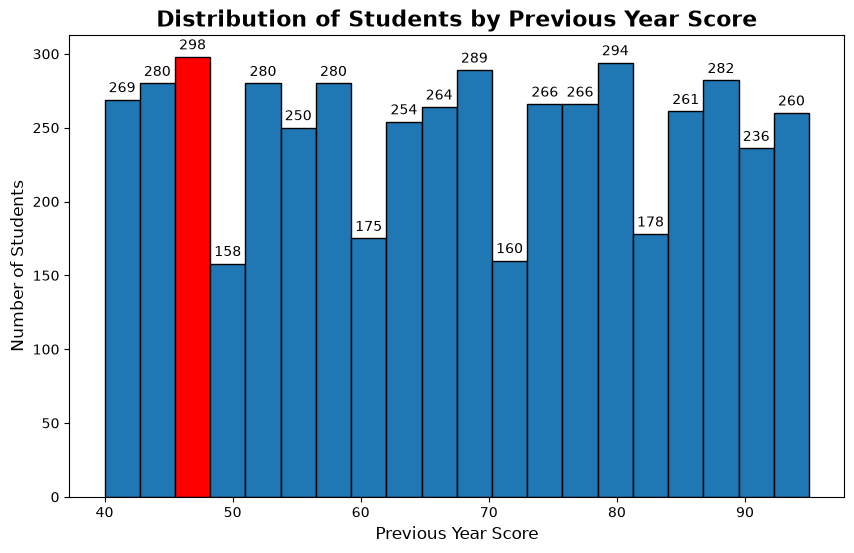

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(
    df['Previous_Year_Score'],
    bins=20,
    edgecolor='black')

highlight_max(ax)
annotate_bars(ax)
title_labels(
    'Distribution of Students by Previous Year Score',
    'Previous Year Score',
    'Number of Students'
)

plt.show()

### Observation

- Previous-year scores are relatively evenly distributed, with student counts ranging from approximately 158 to 298 across the score intervals.
- The 45–48 range has the highest frequency (298 students), while the range around 50 has the lowest (158 students).
- Overall, no specific score range dominates the distribution, although minor dips appear around 50, 60, and 72.

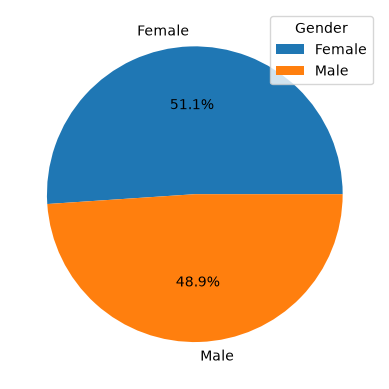

In [24]:
gender_map= {1: 'Male', 0: 'Female'}
plt.pie(
    df['Is_Male'].value_counts(),
    labels=[gender_map[i] for i in df['Is_Male'].value_counts().index],
    autopct= '%1.1f%%'
)
plt.legend(title='Gender', loc='upper right')
plt.show()

### Observations

- 51.1% of students are female.
- 48.9% of students are male.
- The gender distribution is nearly balanced, with a slight majority of female students.

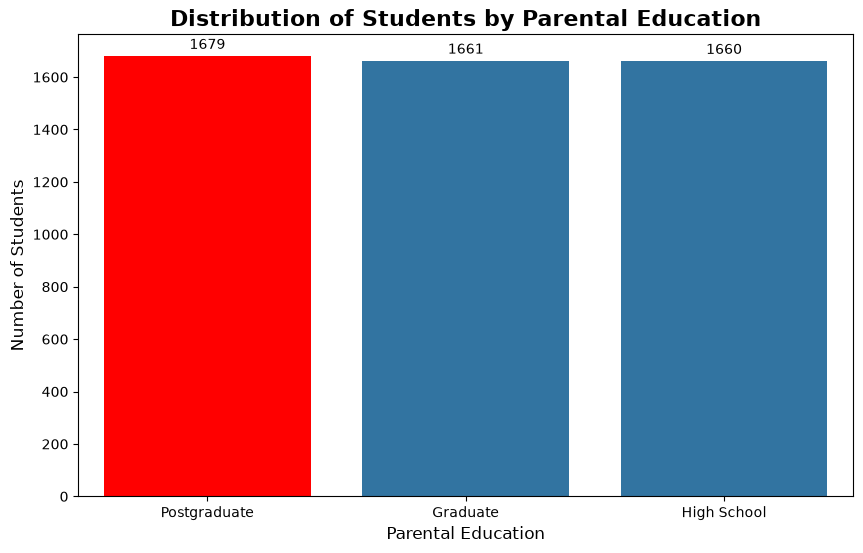

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(
    x = 'Parental_Education',
    data=df,
    ax=ax
)
annotate_bars(ax)
highlight_max(ax)
title_labels(
    'Distribution of Students by Parental Education',
    'Parental Education',
    'Number of Students'
)
plt.show()

### Observations

- Parent education levels are relatively evenly distributed across the categories.
- Postgraduate education has the highest frequency (1,679 students).
- Graduate education follows closely with 1,661 students.
- High school education accounts for 1,660 students.
- Overall, there are no significant differences in the distribution of parent education levels.